# Regresja liniowa — metoda najmniejszych kwadratów (MNK)

W tym notebooku przeprowadzimy **algorytm MNK krok po kroku** na prostym przykładzie:
przewidujemy **cenę mieszkania** na podstawie jego **powierzchni**.

Plan:
1. generujemy dane,
2. dopasowujemy prostą metodą najmniejszych kwadratów,
3. rysujemy prostą i reszty (błędy),
4. oceniamy dopasowanie współczynnikiem R²,
5. przewidujemy cenę konkretnego mieszkania,
6. bonus: sprawdzamy, że wzory z wykładu dają dokładnie ten sam wynik.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

## Krok 1 — dane

Mamy 30 mieszkań. Cena zależy głównie od powierzchni, ale rynek bywa nieprzewidywalny:
stan mieszkania, piętro, dzielnica, targowanie się... Dlatego punkty są mocno **rozbite** —
na pierwszy rzut oka trudno powiedzieć, gdzie powinna przebiegać prosta.

In [2]:
# ziarno losowości — dzięki niemu za każdym razem dostaniemy te same dane
rng = np.random.default_rng(seed=42)

# powierzchnie mieszkań: 30 mieszkań, od 20 do 80 m^2
powierzchnia = rng.uniform(20, 80, size=30)

# cena w tys. zł: 9 tys. za każdy m^2 + 60 tys. "za samo mieszkanie" + duży szum
szum = rng.normal(0, 90, size=30)
cena = 9 * powierzchnia + 60 + szum

# scikit-learn oczekuje cech w formie "kolumny" (macierz 2D)
X = powierzchnia.reshape(-1, 1)
y = cena

print(f"Liczba mieszkań: {len(powierzchnia)}")

Liczba mieszkań: 30


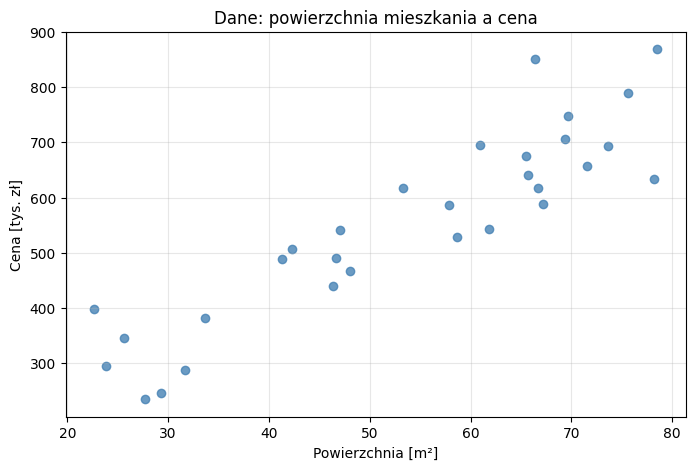

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8)
plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Dane: powierzchnia mieszkania a cena")
plt.grid(alpha=0.3)
plt.show()

## Krok 2 — dopasowujemy prostą (MNK)

**Zanim uruchomisz komórkę: spróbuj zgadnąć, gdzie powinna przebiegać prosta.**

`LinearRegression` z scikit-learn implementuje metodę najmniejszych kwadratów:
szuka takiej prostej, dla której **suma kwadratów reszt jest najmniejsza**.

In [4]:
model = LinearRegression()
model.fit(X, y)

a = model.coef_[0]      # nachylenie: o ile droższe mieszkanie za każdy dodatkowy m^2
b = model.intercept_    # wyraz wolny: "cena startowa" przy zerowej powierzchni

print(f"Dopasowana prosta:  cena = {a:.2f} * powierzchnia + {b:.2f}  [tys. zł]")

Dopasowana prosta:  cena = 8.78 * powierzchnia + 82.07  [tys. zł]


## Krok 3 — prosta na wykresie

Porównaj z Twoim zgadywaniem z Kroku 2 — blisko?

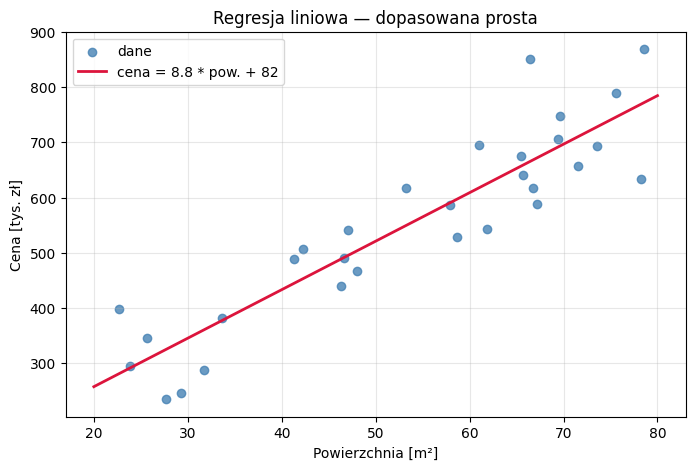

In [5]:
# prosta rysowana od najmniejszej do największej powierzchni
x_linia = np.linspace(20, 80, 100)
y_linia = a * x_linia + b

plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8, label="dane")
plt.plot(x_linia, y_linia, color="crimson", linewidth=2, label=f"cena = {a:.1f} * pow. + {b:.0f}")
plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Regresja liniowa — dopasowana prosta")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Krok 4 — reszty: o ile model się myli

**Reszta = wartość rzeczywista − wartość przewidziana.**
To pionowa odległość punktu od prostej. MNK minimalizuje sumę ich kwadratów.

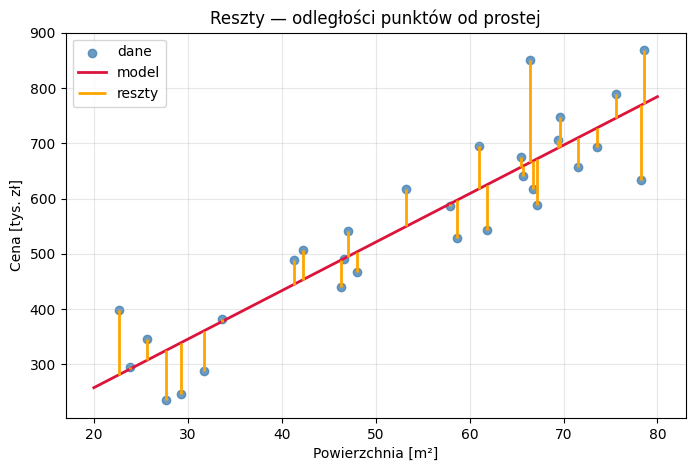

Suma kwadratów reszt: 151667 (tys. zł)^2


In [6]:
y_przewidziane = model.predict(X)
reszty = y - y_przewidziane

plt.figure(figsize=(8, 5))
plt.scatter(powierzchnia, cena, color="steelblue", alpha=0.8, label="dane")
plt.plot(x_linia, y_linia, color="crimson", linewidth=2, label="model")

# pomarańczowe kreski pokazują reszty
plt.vlines(powierzchnia, y, y_przewidziane, color="orange", linewidth=2, label="reszty")

plt.xlabel("Powierzchnia [m²]")
plt.ylabel("Cena [tys. zł]")
plt.title("Reszty — odległości punktów od prostej")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Suma kwadratów reszt: {np.sum(reszty ** 2):.0f} (tys. zł)^2")

## Krok 5 — ocena dopasowania: R²

R² porównuje błąd naszej prostej z błędem "głupiego" modelu, który zawsze zgaduje średnią:
**R² = 1 − (błąd prostej / błąd średniej)**.
R² = 1 → idealnie, R² = 0 → prosta nic nie wnosi.

In [7]:
r2 = r2_score(y, y_przewidziane)

print(f"R² = {r2:.3f}")
print("Im bliżej 1, tym lepiej prosta opisuje dane.")

R² = 0.823
Im bliżej 1, tym lepiej prosta opisuje dane.


## Krok 6 — przewidywanie ceny konkretnego mieszkania

In [8]:
nowe_mieszkanie = np.array([[55]])   # mieszkanie o powierzchni 55 m^2
przewidywana_cena = model.predict(nowe_mieszkanie)[0]

print(f"Mieszkanie 55 m^2 -> przewidywana cena: {przewidywana_cena:.0f} tys. zł")

Mieszkanie 55 m^2 -> przewidywana cena: 565 tys. zł


## Bonus — wzory z wykładu dają ten sam wynik

Przepis z wykładu (bez dowodu):
- a = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²
- b = ȳ − a·x̄

In [9]:
x_srednia = powierzchnia.mean()
y_srednia = cena.mean()

a_recznie = np.sum((powierzchnia - x_srednia) * (cena - y_srednia)) / np.sum((powierzchnia - x_srednia) ** 2)
b_recznie = y_srednia - a_recznie * x_srednia

print(f"scikit-learn:    a = {a:.4f}, b = {b:.4f}")
print(f"wzory z wykładu: a = {a_recznie:.4f}, b = {b_recznie:.4f}")

scikit-learn:    a = 8.7790, b = 82.0737
wzory z wykładu: a = 8.7790, b = 82.0737


## Wnioski

- prosta **cena = a·powierzchnia + b** to nasz model: `a` — o ile droższe mieszkanie za każdy m², `b` — "cena startowa",
- MNK wybiera prostą z **najmniejszą sumą kwadratów reszt**,
- nawet przy mocno rozbitych danych MNK znajduje ukryty trend,
- **R²** bliskie 1 = dobre dopasowanie (ale R² = 1 bywa podejrzane — dane prawdziwe zawsze mają szum),
- model przewiduje **liczby** — to regresja.